I certify that this represents my own work and that I have not worked with classmates
or other individuals to complete this assignment.

Lilo Ryan


Much of the code is adapted from the code provided in class.

In [125]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
import os
from netCDF4 import Dataset
import pandas as pd
import xarray as xr
from scipy.signal import detrend
from scipy.stats import chi2 as chi2_dist


In [ ]:
@dataclass
class WindData:
    dnum: np.ndarray          # times in julian time
    wspeed: np.ndarray   # m/s
    zwind: np.ndarray      # m/s
    mwind: np.ndarray  #m/s

    def __len__(self):
        return len(self.dnum)

    
def get_wind(file):
    """Return different types of wind speed measures from buoy measures.

    Parameters
    ----------
    file : str, optional
        Path to the netCDF file. 

    Returns
    -------
    wind : WindData
    """

    nc = Dataset(file)
    try:
        #fill_value = 9.969209968386869e36 #have to convert from julian date formatting to standard datetime
        #time_data = np.where(nc["TIME"] == fill_value, np.nan, nc["TIME"])
        #time_d = pd.to_datetime(time_data, unit="D", origin = "1950-01-01 00:00:00")
        #dnum = np.array(time_d.values)#.astype('datetime64[m]')
        dnum = np.ndarray.flatten(np.asarray(nc.variables['TIME'][:]))
        wspeed = np.ndarray.flatten(np.asarray(nc.variables['WSPD'][:]))
        zwind = np.ndarray.flatten(np.asarray(nc.variables['UWND'][:]))
        mwind = np.ndarray.flatten(np.asarray(nc.variables['VWND'][:]))

        #process and interpolate in advance
        nand = np.where(wspeed == -999.0, np.nan, wspeed)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            dnum = dnum[0:47581]
            cleaned_np_array = cleaned_np_array[0:47581]
        wspeed = cleaned_np_array

        nand = np.where(zwind == -999.0, np.nan, zwind)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        zwind = cleaned_np_array


        nand = np.where(mwind == -999.0, np.nan, mwind)
        da = xr.DataArray(nand, dims="ws")
        
        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        mwind = cleaned_np_array

    finally:
        nc.close()

    i1 = np.ones(dnum.shape, dtype=bool)

    return WindData(dnum=dnum[i1][:],
                    wspeed=wspeed[i1][:],
                    zwind=zwind[i1][:],
                    mwind = mwind[i1][:])


# Question 1

In [127]:
w2015 = get_wind("../HW5_data/OS_T8S110W_DM134A-20150425_D_WIND_10min.nc")
w2016 = get_wind("../HW5_data/OS_T8S110W_DM183A-20160321_D_WIND_10min.nc")
w2017 = get_wind("../HW5_data/OS_T8S110W_DM231A-20170606_D_WIND_10min.nc")

In [128]:
diffs15 = []
for i in range(1,len(w2015.dnum)):
    diffs15.append(w2015.dnum[i]-w2015.dnum[i-1])
diffs15 = np.array(diffs15)
diffs15 = diffs15 *24 * 60
diffs15

array([10., 10., 10., ..., 10., 10., 10.], shape=(47580,))

The length of time between each interval is 10 minutes.

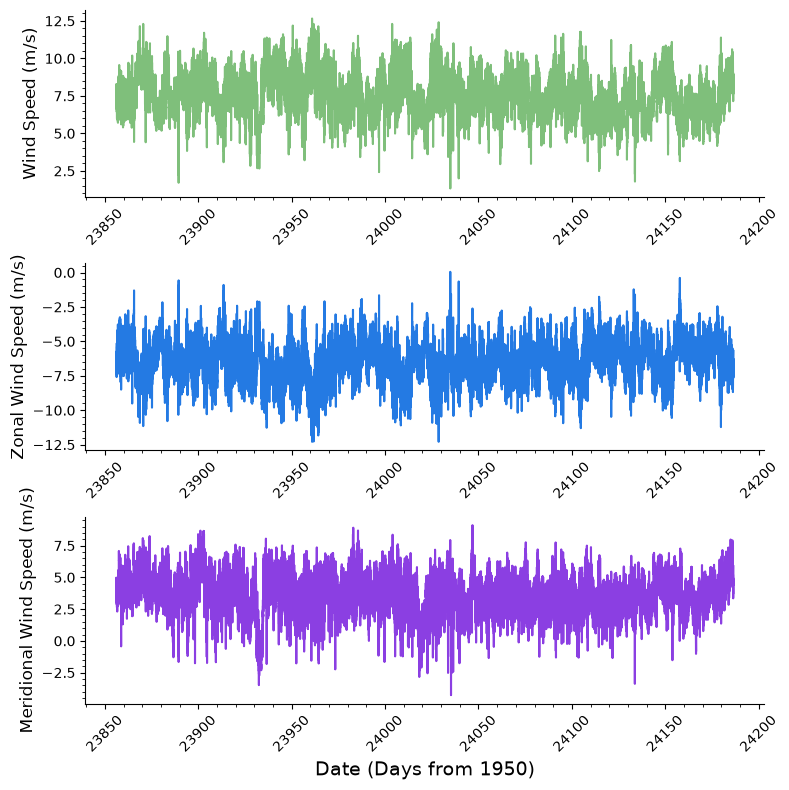

In [129]:
fig, axs = plt.subplots(nrows= 3,ncols = 1, figsize = (8,8))
axs[0].plot(w2015.dnum, w2015.wspeed, color = "#7fbf7b")

axs[0].minorticks_on()
axs[0].set_ylabel("Wind Speed (m/s)", fontsize = 12)
axs[0].tick_params(axis='x', labelrotation=45)
axs[0].spines[['top', 'right']].set_visible(False)

axs[1].plot(w2015.dnum, w2015.zwind, color = "#247ae3")

axs[1].minorticks_on()
axs[1].set_ylabel("Zonal Wind Speed (m/s)", fontsize = 12)
axs[1].tick_params(axis='x', labelrotation=45)
axs[1].spines[['top', 'right']].set_visible(False)

axs[2].plot(w2015.dnum, w2015.mwind, color = "#8b3fe2")
axs[2].set_xlabel("Date (Days from 1950)", fontsize = 14)
axs[2].minorticks_on()
axs[2].set_ylabel("Meridional Wind Speed (m/s)", fontsize = 12)
axs[2].tick_params(axis='x', labelrotation=45)
axs[2].spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [130]:
w1516 = (w2016.dnum[0] - w2015.dnum[-1])*24
w1617 = (w2017.dnum[0] - w2016.dnum[-1])*24
w1516, w1617

(np.float64(13.5), np.float64(22.16666666662786))

The gaps were filled by values of -999.0 meters/second. There is a gap of 9.50 hours between the 2015 and 2016 datasets and a gap of 22.17 hours between the 2016 and 2017 datasets.

# Question 2

In [ ]:
def segmenter(x, window=8640, step =4320): #got numbers by converting 30 and 60 days into number of data points
    arr = np.lib.stride_tricks.sliding_window_view(x, window_shape=window)[::step]
    return arr

In [151]:
s15d = segmenter(w2015.dnum)
s15w = segmenter(w2015.wspeed)
s15z = segmenter(w2015.zwind)
s15m = segmenter(w2015.mwind)

s16d = segmenter(w2016.dnum)
s16w = segmenter(w2016.wspeed)
s16z = segmenter(w2016.zwind)
s16m = segmenter(w2016.mwind)

s17d = segmenter(w2017.dnum)
s17w = segmenter(w2017.wspeed)
s17z = segmenter(w2017.zwind)
s17m = segmenter(w2017.mwind)

In [133]:
1/(10*6*24*2)



0.00034722222222222224

Each segment has 8640 elements in it. There are 10 segments for 2015, 13 segments for 2016, and 9 segments for 2017. The Nyquist frequency is 0.00035 cycles per day and the fundamental frequency is 0.016 cycles per day.

# Question 3

In [134]:
# raw data
a = np.fft.fft(w2015.wspeed)
N = len(w2015.wspeed)
amp = np.abs(a[:(N+1)//2 + 1])**2 

dt = 10/(60*24)
T = dt*N
df = 1/T
fn = 1/2/dt
f = np.arange(0, ((N + 1) // 2 + 1) * df, df) 

amp = amp / N**2 
amp[1:-1] = amp[1:-1]*2 
amp = amp / df

In [135]:
#detrended data
deW = detrend(w2015.wspeed) 

b = np.fft.fft(deW)
N = len(deW)
amp1 = np.abs(b[:(N+1)//2 + 1])**2 

dt = 10/(60*24)
T = dt*N
df = 1/T
fn = 1/2/dt
f = np.arange(0, ((N + 1) // 2 + 1) * df, df) 

amp1 = amp1 / N**2 
amp1[1:-1] = amp1[1:-1]*2 
amp1 = amp1 / df

In [136]:
#hanning window detrended
#as found above M is 10
M = 10
p = N//M
s15w = segmenter(detrend(w2015.wspeed))
w = np.hanning(p) # matches MATLAB's hann, not its hanning
scale = np.sqrt(8/3) # put back the energy the taper removed
starts = np.arange(0, N - p + 1, p//2)
Sc = np.zeros((p//2 + 1, len(starts)))
for k, s in enumerate(starts):
    sgi = detrend(deW[s:s+p])
    Xc = np.fft.fft(sgi*w*scale)
    tmp = np.abs(Xc[:p//2+1])**2 / p**2; tmp[1:-1] *= 2
    Sc[:, k] = tmp/(1/(dt*p))
Sc = np.mean(Sc, axis=1)
fbv = np.arange(0, fn + 1/(dt*p)/2, 1/(dt*p))


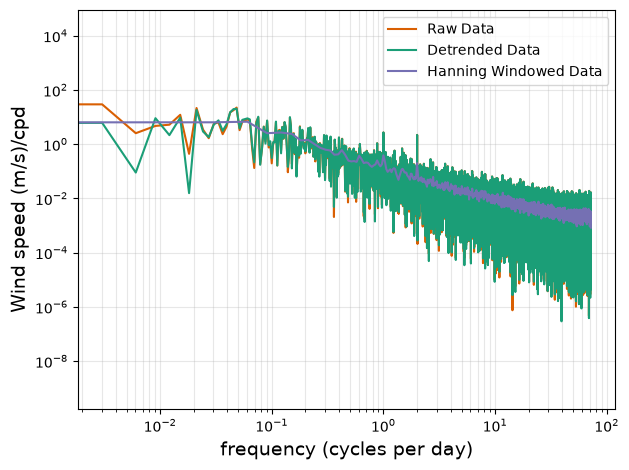

In [137]:
fig, ax = plt.subplots()
ax.loglog(f, amp, color = "#d95f02", label = "Raw Data")
ax.loglog(f, amp1, color = "#1b9e77", label = "Detrended Data")
ax.loglog(fbv, Sc, color = "#7570b3", label = "Hanning Windowed Data")
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Wind speed (m/s)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

Detrending honestly does not alter the spectrum to a high degree. It slightly makes peaks at higher frequencies more visible. Taking the Hanning window makes a great deal of difference. It significantly reduces the magnitude of variation in lower frequencies.

# Question 4

In [138]:
nu = 20 # 2 times M segments
err_high = nu/chi2_dist.ppf(.05/2, nu)
err_low = nu/chi2_dist.ppf(1 - .05/2, nu)
print(f'nu = {nu:2d}: factor {err_low:.3f} to {err_high:.2f} (ratio {err_high/err_low:.0f})')
indf = int(np.argmax(fbv > 12)) # remove low frequency noise

nu = 20: factor 0.585 to 2.09 (ratio 4)


In [139]:
nu1 = 2 # 2 times M segments
err_high1 = nu1/chi2_dist.ppf(.05/2, nu1)
err_low1 = nu1/chi2_dist.ppf(1 - .05/2, nu1)
print(f'nu = {nu1:2d}: factor {err_low1:.3f} to {err_high1:.2f} (ratio {err_high1/err_low1:.0f})')
indf1 = int(np.argmax(f > 12)) # remove low frequency noise

nu =  2: factor 0.271 to 39.50 (ratio 146)


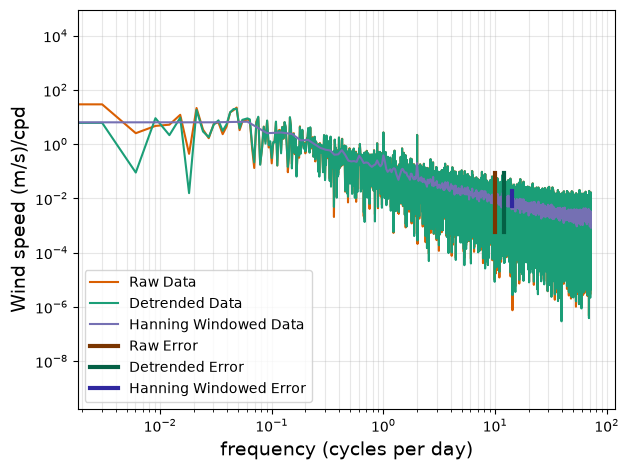

In [140]:
fig, ax = plt.subplots()
ax.loglog(f, amp, color = "#d95f02", label = "Raw Data")
ax.loglog(f, amp1, color = "#1b9e77", label = "Detrended Data")
ax.loglog(fbv, Sc, color = "#7570b3", label = "Hanning Windowed Data")
ax.plot([f[indf1]-2]*2, [err_low1*amp[indf1], err_high1*amp[indf1]],color =  "#7a3500", label = "Raw Error", lw=3)
ax.plot([f[indf1]]*2, [err_low1*amp1[indf1], err_high1*amp1[indf1]],color =  "#046045", label = "Detrended Error", lw=3)
ax.plot([fbv[indf]+2]*2, [err_low*Sc[indf], err_high*Sc[indf]],color =  "#2f279f", label = "Hanning Windowed Error", lw=3)

ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Wind speed (m/s)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

The error bars for the raw and detrended data will be the same-- there are two degrees of freedom for both and the amplitude for both will be incredibly similar. The Hanning windowed data has smaller error bars because the number of degrees of freedom is 20. This visually makes sense as there is less visible variation in the data that had the Hanning Window applied to it. 

# Question 5

In [141]:
def detHan(data, samples, interval = 10/(60*24), detrended = True):
    if detrended == False:
        deT = detrend(data)
    else:
        deT = data
    M = samples
    p = len(data)//M 
    fn = 1/2/interval
    w = np.hanning(p) # matches MATLAB's hann, not its hanning
    scale = np.sqrt(8/3) # put back the energy the taper removed
    starts = np.arange(0, len(data) - p + 1, p//2)
    Sc = np.zeros((p//2 + 1, len(starts)))
    for k, s in enumerate(starts):
        sgi = detrend(deT[s:s+p])
        Xc = np.fft.fft(sgi*w*scale)
        tmp = np.abs(Xc[:p//2+1])**2 / p**2; tmp[1:-1] *= 2
        Sc[:, k] = tmp/(1/(interval*p))
    Sc = np.mean(Sc, axis=1)
    fbv = np.arange(0, fn + 1/(interval*p)/2, 1/(interval*p))

    #uncertainties
    nu = 2*M # 2 times M segments
    err_high = nu/chi2_dist.ppf(.05/2, nu)
    err_low = nu/chi2_dist.ppf(1 - .05/2, nu)
    indf = int(np.argmax(fbv > 12)) # remove low frequency noise


    coords = [fbv, Sc]
    uncert = [err_high, err_low, indf]
    return coords, uncert

def nonHan(data, interval = 10/(60*24)):
    a = np.fft.fft(data)
    N = len(data)
    amp = np.abs(a[:(N+1)//2 + 1])**2 

    dt = interval
    T = dt*N
    df = 1/T
  
    f = np.arange(0, ((N + 1) // 2 + 1) * df, df) 

    amp = amp / N**2 
    amp[1:-1] = amp[1:-1]*2 
    amp = amp / df

    #uncert
    nu = 2 # 2 times M segments (only one segment)
    err_high = nu/chi2_dist.ppf(.05/2, nu)
    err_low = nu/chi2_dist.ppf(1 - .05/2, nu)

    indf = int(np.argmax(fbv > 12)) # remove low frequency noise
    coords = [f, amp]
    uncert = [err_high, err_low, indf]
    return coords, uncert

In [142]:
s15w, un15w = detHan(deW, 10)
s15m, un15m = detHan(w2015.mwind, 10, detrended= False)
s15z, un15z = detHan(w2015.zwind, 10, detrended= False)

In [143]:
s16w, un16w = detHan(w2016.wspeed, 13, detrended= False)
s16m, un16m = detHan(w2016.mwind, 13, detrended= False)
s16z, un16z = detHan(w2016.zwind, 13, detrended= False)

In [144]:
s17w, un17w = detHan(w2017.wspeed, 9, detrended= False)
s17m, un17m = detHan(w2015.mwind, 9, detrended= False)
s17z, un17z = detHan(w2015.zwind, 9, detrended= False)

Since we unfortunately have different scales/number of data points for each of the years, we have to additionally interpolate to get all on the same frequency scale for averaging.

In [145]:
s16w = np.interp(fbv, s16w[0], s16w[1])
s17w = np.interp(fbv, s17w[0], s17w[1])

s16m = np.interp(fbv, s16m[0], s16m[1])
s17m = np.interp(fbv, s17m[0], s17m[1])

s16z = np.interp(fbv, s16z[0], s16z[1])
s17z = np.interp(fbv, s17z[0], s17z[1])


In [146]:
wsps = np.mean([s15w[1], s16w, s17w],axis=0)
mws = np.mean([s15m[1], s16m, s17m], axis = 0)
zws = np.mean([s15z[1], s16z, s17z], axis = 0)


In [147]:
indf_overall = int(np.argmax(fbv > 12))
nu3 = 2*(10+13+9) # 2 times M segments
err_high_o = nu3/chi2_dist.ppf(.05/2, nu3)
err_low_o = nu3/chi2_dist.ppf(1 - .05/2, nu3)


unc_tot = [err_high_o, err_low_o, indf_overall]

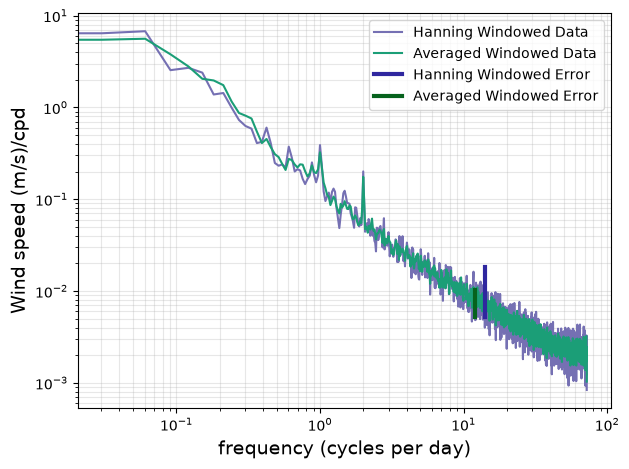

In [148]:
fig, ax = plt.subplots()

ax.loglog(fbv, Sc, color = "#7570b3", label = "Hanning Windowed Data")
ax.loglog(fbv, wsps, color = "#1b9e77", label = "Averaged Windowed Data")

ax.plot([fbv[indf]+2]*2, [err_low*Sc[indf], err_high*Sc[indf]],color =  "#2f279f", label = "Hanning Windowed Error", lw=3)
ax.plot([fbv[indf_overall]]*2, [err_low_o*wsps[indf_overall], err_high_o*wsps[indf_overall]],color =  "#06621d", label = "Averaged Windowed Error", lw=3)
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Wind speed (m/s)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

The averaged spectra has even less variation than the 2015 only spectrum. The data is averaged over the three years, which should mean that only the true peaks are visible in the plot. The differences can partially be explained by differences in the uncertainties, but it is also important to understand that, with the addition of multiple years, the peaks should be more accurate to the true frequencies and not simply noise. 

In [149]:

idx_1cpd = np.argmin(np.abs(fbv - 1.0))
idx_2cpd = np.argmin(np.abs(fbv - 2.0))

print(
    f"Closest frequency to Diurnal cycle: {fbv[idx_1cpd]:.4f} cpd (index {idx_1cpd})"
)
print(
    f"Closest frequency to Semidiurnal cycle: {fbv[idx_2cpd]:.4f} cpd (index {idx_2cpd})\n"
)


Closest frequency to Diurnal cycle: 0.9987 cpd (index 33)
Closest frequency to Semidiurnal cycle: 1.9975 cpd (index 66)



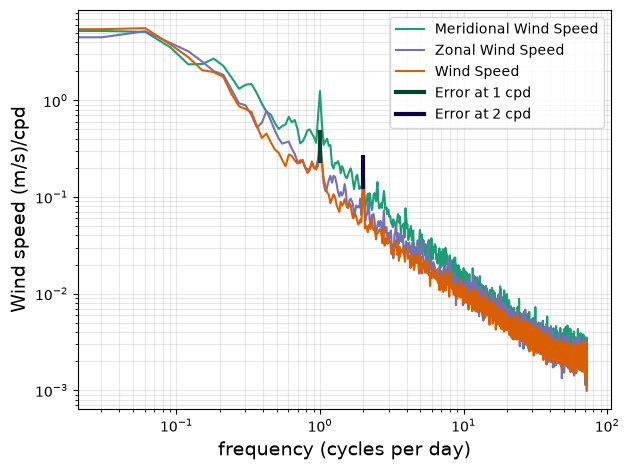

In [150]:
fig, ax = plt.subplots()

ax.loglog(fbv, mws, color = "#1b9e77", label = "Meridional Wind Speed")

ax.loglog(fbv, zws, color = "#7570b3", label = "Zonal Wind Speed")
ax.loglog(fbv, wsps, color = "#d95f02", label = "Wind Speed")
ax.plot([fbv[33]]*2, [err_low_o*wsps[33], err_high_o*wsps[33]],color =  "#024430", label = "Error at 1 cpd", lw=3)
ax.plot([fbv[66]]*2, [err_low_o*wsps[66], err_high_o*wsps[66]],color =  "#0B0244", label = "Error at 2 cpd", lw=3)
#ax.plot([f[indf1]]*2, [err_low1*amp1[indf1], err_high1*amp1[indf1]],color =  "#046045", label = "Detrended Error", lw=3)
#ax.plot([fbv[indf]+2]*2, [err_low*Sc[indf], err_high*Sc[indf]],color =  "#2f279f", label = "Hanning Windowed Error", lw=3)

ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Wind speed (m/s)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

The Zonal andd Meridional wind appears to be equivalent at 2 cycles per day, while the meridional is much higher speed than zonal at 1 cycle per day. The total wind speed follows the zonal at 1 cycle per day and agrees with the meridional and zonal at 2 cycles per day. Looking at the error bars, the Meridional wind speed is significantly different from the zonal and total wind speed at 1 cpd (diurnal). At 2 cpd, none of the wind measurements are significantly different from each other. I imagine that there could be larger impacts daily (i.e. a specific requirement of a time of day) such that heating or cooling only happens once a day. This would need to happen in a way that impacts the direction of wind flow. This would explain why the semi-diurnal does not have significant differences between the zonal vs meridional winds.